# Первый baseline

## 1. Зафиксированный эксперимент

Подготовка сохранена коммитом `6cea578`. Проверяем константный прогноз из
частоты train и логистическую регрессию L2 для geometry / geometry_aircraft.
Все записи одинаковы, split и обработка признаков из ноутбуков 06–07.
Bearing, AC_CLASS, market_segment, идентификаторы и будущие даты не предикторы.

Сетка C = 0.01, 0.1, 1, 10; выбор по AP validation, при равенстве меньший C.
Fit только train, без class_weight и без refit train+validation. Порог —
максимальный F1 validation, при равенстве более высокий. Это исследовательский
критерий, не оценка эксплуатационной стоимости тревог.

После выбора сохраняем решение до расчета test-метрик. Test не влияет на
выбор набора, регуляризации или порога. На нем описываем обе заранее заданные
модели и константный ориентир. Парный bootstrap недель C40 UTC: 1000, seed=42.
Это условные интервалы фиксированных моделей, не вся неопределенность обучения.

**Ретроспективный статус:** историческое время получения признаков не подтверждено.
Test — часть 2023 года, преимущественно знакомый парк, без EGCC. Выборка A
отобрана по наличию C40; результаты не распространяются на все исходные события.

[LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html):
используем разреженную матрицу и solver newton-cholesky, подходящий для числа
записей значительно больше числа признаков. Достижение сходимости проверяется.
Кеш локальных коэффициентов привязан к входам и параметрам, чтобы восстановить
расчет после прерывания, не меняя протокол по результату test.

In [1]:
from pathlib import Path
import os,hashlib,json,time,warnings,platform,importlib.metadata
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import pyarrow as pa
from scipy import sparse
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score,roc_auc_score,brier_score_loss,precision_recall_curve,roc_curve
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/preparation_plan.json').exists():
    if ROOT==ROOT.parent:raise FileNotFoundError('Сначала выполните 06–07')
    ROOT=ROOT.parent
R=ROOT/'reports';F=ROOT/'figures';LOCAL=ROOT/'data';MODELS=LOCAL/'baseline_models';MODELS.mkdir(exist_ok=True)
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
plan=json.loads((R/'preparation_plan.json').read_text(encoding='utf-8'))
protocol=json.loads((R/'protocol_manifest.json').read_text(encoding='utf-8'))
entry=next(x for x in json.loads((R/'verification.json').read_text(encoding='utf-8'))['inputs'] if x['stage']=='final')
DATA=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))/entry['file'].replace(chr(92),'/')
if not DATA.exists():DATA=LOCAL/'06_05_cases_excluded.parquet'
split_path=LOCAL/'06_candidate_split_labels.parquet'
assert sha(DATA)==plan['input_sha256'] and sha(split_path)==plan['split_file_sha256']
assert protocol['structural_checks_passed']
vocab=json.loads((R/'preparation_train_vocabulary.json').read_text(encoding='utf-8'))['vocabulary']
scaler=json.loads((R/'preparation_numeric_scaler.json').read_text(encoding='utf-8'))['parameters']
labels=pq.read_table(split_path).to_pandas()
assert np.array_equal(labels.source_row,np.arange(len(labels)))
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
COLORS={'constant':'#546E63','geometry':'#00897B','geometry_aircraft':'#D65A4A'}
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
environment={k:importlib.metadata.version(k) for k in ['numpy','pandas','scipy','scikit-learn','threadpoolctl','pyarrow']}
solver_config={'solver':'newton-cholesky','l1_ratio':0.0,'tol':1e-7,'max_iter':100,'random_state':42,'class_weight':None}
signature=hashlib.sha256(json.dumps({'input':plan['input_sha256'],'split':plan['split_file_sha256'],
 'vocab':vocab,'scaler':scaler,'solver':solver_config,'environment':environment,
 'encoding_version':'onehot_reserved_states_v1','plan':plan},sort_keys=True).encode()).hexdigest()


## 2. Матрица без будущих полей

Категории train имеют свои колонки; missing и unseen получают по отдельной
резервной колонке. Индексы категорий не являются числовой шкалой. UTC weekday
кодируется семью фиксированными колонками, час — sin / cos секунд суток.
Lat / lon стандартизируются по параметрам train. Test-метки не читаются при
выборе параметров, кроме неизмененного полного файла; вычисления selection
получают только y train / validation.

In [2]:
parts=['train','validation','test'];chunks={s:[] for s in parts};metadata={s:[] for s in parts}
cats=['airport','typecode','icaoaircrafttype'];feature_names=[];cat_slices={}
for f in cats:
    start=len(feature_names)
    feature_names += [f+':'+x for x in vocab[f]]+[f+':<MISSING>',f+':<UNSEEN>']
    cat_slices[f]=slice(start,len(feature_names))
num_names=['lat_z','lon_z','utc_time_sin','utc_time_cos']+[f'utc_weekday:{i}' for i in range(7)]
numeric_start=len(feature_names);feature_names+=num_names
maps={f:{v:i for i,v in enumerate(vocab[f])} for f in cats}
def make_matrix(d):
    n=len(d);blocks=[]
    for f in cats:
        codes=d[f].map(maps[f]).fillna(len(vocab[f])+1).to_numpy(dtype=np.int32)
        missing=d[f].isna()|d[f].eq('').fillna(False)
        codes[missing.to_numpy()]=len(vocab[f])
        blocks.append(sparse.csr_matrix((np.ones(n),(np.arange(n),codes)),shape=(n,len(vocab[f])+2)))
    t=d.C40_CROSS_TIME;seconds=t.dt.hour*3600+t.dt.minute*60+t.dt.second+t.dt.microsecond/1e6
    phase=2*np.pi*seconds.to_numpy()/86400
    numeric=np.column_stack([(d.C40_CROSS_LAT.to_numpy()-scaler['C40_CROSS_LAT']['mean'])/scaler['C40_CROSS_LAT']['scale'],
                            (d.C40_CROSS_LON.to_numpy()-scaler['C40_CROSS_LON']['mean'])/scaler['C40_CROSS_LON']['scale'],
                            np.sin(phase),np.cos(phase)])
    assert np.isfinite(numeric).all()
    blocks.append(sparse.csr_matrix(numeric))
    blocks.append(sparse.csr_matrix((np.ones(n),(np.arange(n),t.dt.dayofweek.to_numpy())),shape=(n,7)))
    return sparse.hstack(blocks,format='csr',dtype=np.float64)
reader=pq.ParquetFile(DATA);offset=0
for batch in reader.iter_batches(batch_size=200000,columns=cats+['C40_CROSS_LAT','C40_CROSS_LON','C40_CROSS_TIME','GoA']):
    d=batch.to_pandas();status=labels.split.iloc[offset:offset+len(d)].to_numpy()
    ordinal=np.arange(offset,offset+len(d));offset+=len(d)
    for s in parts:
        mask=status==s;a=d[mask]
        if len(a):
            chunks[s].append(make_matrix(a))
            m=a[['airport','C40_CROSS_TIME','GoA']].copy();m['source_row']=ordinal[mask];metadata[s].append(m)
del reader
X={s:sparse.vstack(chunks[s],format='csr') for s in parts}
meta={s:pd.concat(metadata[s],ignore_index=True) for s in parts};del chunks,metadata,labels
indices={'geometry':np.r_[np.arange(cat_slices['airport'].start,cat_slices['airport'].stop),np.arange(numeric_start,len(feature_names))],
         'geometry_aircraft':np.arange(len(feature_names))}
assert offset==entry['rows'] and all(X[s].shape[1]==len(feature_names) for s in parts)
split_expected=pd.read_csv(R/'protocol_split_summary.csv').set_index('split')
for s in parts:
    assert X[s].shape[0]==split_expected.loc[s,'rows'] and int(meta[s].GoA.sum())==split_expected.loc[s,'goa']
pd.DataFrame([{'split':s,'rows':X[s].shape[0],'columns':X[s].shape[1],'nnz':X[s].nnz} for s in parts]).to_csv(R/'baseline_matrix_summary.csv',index=False)
display(pd.read_csv(R/'baseline_matrix_summary.csv'))


,split,rows,columns,nnz
0,train,4161493,380,33291939
1,validation,1619847,380,12958774
2,test,546577,380,4372614


## 3. Обучение и выбор только на validation

Каждый C обучается на полном train. Сходимость — необходимое условие допуска
к сравнению. Решение и validation-порог записываются перед test-расчетом.
Повторный запуск может читать только совпадающий по сигнатуре локальный кеш
коэффициентов; его наличие не заменяет проверку числа признаков.

In [3]:
def choose_threshold(y,p):
    precision,recall,thresholds=precision_recall_curve(y,p)
    f1=np.divide(2*precision[:-1]*recall[:-1],precision[:-1]+recall[:-1],
                 out=np.zeros_like(thresholds),where=(precision[:-1]+recall[:-1])>0)
    best=np.flatnonzero(f1==f1.max())[-1]
    return float(thresholds[best]),float(f1[best])
models={};validation_predictions={};search=[];chosen={}
ytrain=meta['train'].GoA.to_numpy(dtype=np.int8);yvalid=meta['validation'].GoA.to_numpy(dtype=np.int8)
constant=float(ytrain.mean());validation_predictions['constant']=np.full(len(yvalid),constant)
thresholds={'constant':choose_threshold(yvalid,validation_predictions['constant'])[0]}
for name in plan['primary_comparison']:
    cols=indices[name];xt=X['train'][:,cols];xv=X['validation'][:,cols]
    candidates=[]
    for C in plan['model_plan']['C_grid']:
        cache=MODELS/f'{name}_C{C:g}.json';started=time.perf_counter();cached=False
        if cache.exists():
            result=json.loads(cache.read_text(encoding='utf-8'))
            cached=result.get('signature')==signature and result.get('converged',False)
        if not cached:
            estimator=LogisticRegression(C=C,**solver_config)
            with threadpool_limits(limits=4),warnings.catch_warnings(record=True) as notes:
                warnings.simplefilter('always',ConvergenceWarning);estimator.fit(xt,ytrain)
            converged=not any(issubclass(x.category,ConvergenceWarning) for x in notes)
            assert converged,f'{name} C={C}: сходимость не достигнута, test не открывается'
            result={'signature':signature,'model':name,'C':C,'coef':estimator.coef_[0].tolist(),
                    'intercept':float(estimator.intercept_[0]),'iterations':int(estimator.n_iter_[0]),
                    'converged':True,'fit_rows':len(ytrain)}
            cache.write_text(json.dumps(result,indent=2),encoding='utf-8')
        assert len(result['coef'])==len(cols) and result['fit_rows']==len(ytrain)
        p=expit(xv@np.asarray(result['coef'])+result['intercept'])
        ap=float(average_precision_score(yvalid,p));auc=float(roc_auc_score(yvalid,p))
        search.append({'model':name,'C':C,'validation_AP':ap,'validation_ROC_AUC':auc,
                       'iterations':result['iterations'],'converged':True,'seconds':time.perf_counter()-started,'cached':cached})
        pd.DataFrame(search).to_csv(R/'baseline_validation_search.csv',index=False)
        candidates.append((ap,C,result,p))
        print(f'{name}: C={C:g}; validation AP={ap:.6f}',flush=True)
    best=sorted(candidates,key=lambda x:(-x[0],x[1]))[0]
    models[name]=best[2];validation_predictions[name]=best[3]
    thresholds[name],f1=choose_threshold(yvalid,best[3])
    chosen[name]={'C':best[1],'validation_AP':best[0],'threshold':thresholds[name],'validation_F1':f1}
    del xt,xv,candidates
selection={'signature':signature,'chosen':chosen,'constant_probability':constant,
 'constant_threshold':thresholds['constant'],'selection_split':'validation','test_used_for_selection':False}
(R/'baseline_frozen_selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
display(pd.DataFrame(search));display(pd.DataFrame(chosen).T)


geometry: C=0.01; validation AP=0.003732


geometry: C=0.1; validation AP=0.003711


geometry: C=1; validation AP=0.003706


geometry: C=10; validation AP=0.003705


geometry_aircraft: C=0.01; validation AP=0.004109


geometry_aircraft: C=0.1; validation AP=0.004144


geometry_aircraft: C=1; validation AP=0.004121


geometry_aircraft: C=10; validation AP=0.004098


,model,C,validation_AP,validation_ROC_AUC,iterations,converged,seconds,cached
0,geometry,0.01,0.003732,0.569868,8,True,7.504375,False
1,geometry,0.10,0.003711,0.569126,8,True,7.354969,False
2,geometry,1.00,0.003706,0.568981,8,True,7.590820,False
3,geometry,10.00,0.003705,0.568955,8,True,7.237688,False
4,geometry_aircraft,0.01,0.004109,0.583567,8,True,11.325618,False
5,geometry_aircraft,0.10,0.004144,0.585495,8,True,11.499124,False
6,geometry_aircraft,1.00,0.004121,0.584978,8,True,10.603865,False
7,geometry_aircraft,10.00,0.004098,0.584516,9,True,12.007561,False


,C,validation_AP,threshold,validation_F1
geometry,0.01,0.003732,0.003323,0.007987
geometry_aircraft,0.10,0.004144,0.004728,0.010110


## 4. Оценка фиксированных моделей

Сравнение на одинаковых наблюдениях. Константный прогноз на validation выбирает
порог, который объявляет тревогу для всех: это свойство F1 при редкой метке,
а не полезная эксплуатационная политика. Добавляем долю тревог и матрицу ошибок.
Калибровка: общие фиксированные интервалы вероятностей; пустые интервалы остаются
отсутствующими. У групп с одной меткой ROC-AUC не вычисляется.

In [4]:
assert json.loads((R/'baseline_frozen_selection.json').read_text())['signature']==signature
ytest=meta['test'].GoA.to_numpy(dtype=np.int8)
test_predictions={'constant':np.full(len(ytest),constant)}
for name,result in models.items():
    test_predictions[name]=expit(X['test'][:,indices[name]]@np.asarray(result['coef'])+result['intercept'])
def measure(y,p,threshold):
    predicted=p>=threshold;tp=int((predicted&(y==1)).sum());fp=int((predicted&(y==0)).sum())
    fn=int((~predicted&(y==1)).sum());tn=int((~predicted&(y==0)).sum());positive=int(y.sum())
    return {'rows':len(y),'goa':positive,'AP':float(average_precision_score(y,p)) if positive else np.nan,
            'ROC_AUC':float(roc_auc_score(y,p)) if 0<positive<len(y) else np.nan,
            'Brier':float(brier_score_loss(y,p)),'mean_probability':float(p.mean()),'prevalence':float(y.mean()),
            'threshold':threshold,'precision':tp/(tp+fp) if tp+fp else np.nan,
            'recall':tp/positive if positive else np.nan,'alert_rate':float(predicted.mean()),
            'tp':tp,'fp':fp,'fn':fn,'tn':tn}
metrics=[];airports=[];calibration=[]
bins=np.array([0,.001,.002,.003,.005,.01,.02,.05,.1,.2,.5,1])
for s,y,predictions in [('validation',yvalid,validation_predictions),('test',ytest,test_predictions)]:
    for name,p in predictions.items():
        assert len(p)==len(y) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
        metrics.append({'split':s,'model':name,**measure(y,p,thresholds[name])})
        if s=='test':
            for airport in sorted(meta[s].airport.unique()):
                mask=meta[s].airport.eq(airport).to_numpy()
                airports.append({'airport':airport,'model':name,**measure(y[mask],p[mask],thresholds[name])})
        codes=np.minimum(np.searchsorted(bins,p,side='right')-1,len(bins)-2)
        for b in range(len(bins)-1):
            mask=codes==b
            if mask.any():calibration.append({'split':s,'model':name,'lower':bins[b],'upper':bins[b+1],
                'rows':int(mask.sum()),'goa':int(y[mask].sum()),'mean_predicted':float(p[mask].mean()),'observed':float(y[mask].mean())})
metrics=pd.DataFrame(metrics);airports=pd.DataFrame(airports);calibration=pd.DataFrame(calibration)
metrics.to_csv(R/'baseline_metrics.csv',index=False);airports.to_csv(R/'baseline_airport_metrics.csv',index=False)
calibration.to_csv(R/'baseline_calibration.csv',index=False);display(metrics.style.format(precision=6))
pred=meta['test'][['source_row','airport','C40_CROSS_TIME','GoA']].copy()
for name,p in test_predictions.items():pred[name]=p
prediction_path=LOCAL/'08_test_predictions.parquet';pq.write_table(pa.Table.from_pandas(pred,preserve_index=False),prediction_path,compression='zstd')


,split,model,rows,goa,AP,ROC_AUC,Brier,mean_probability,prevalence,threshold,precision,recall,alert_rate,tp,fp,fn,tn
0,validation,constant,1619847,4984,0.003077,0.500000,0.003067,0.002792,0.003077,0.002792,0.003077,1.000000,1.000000,4984,1614863,0,0
1,validation,geometry,1619847,4984,0.003732,0.569868,0.003067,0.002784,0.003077,0.003323,0.004040,0.350522,0.266977,1747,430715,3237,1184148
2,validation,geometry_aircraft,1619847,4984,0.004144,0.585495,0.003067,0.002775,0.003077,0.004728,0.006075,0.030096,0.015243,150,24541,4834,1590322
3,test,constant,546577,1739,0.003182,0.500000,0.003172,0.002792,0.003182,0.002792,0.003182,1.000000,1.000000,1739,544838,0,0
4,test,geometry,546577,1739,0.003759,0.562344,0.003171,0.002881,0.003182,0.003323,0.004083,0.441633,0.344171,768,187348,971,357490
5,test,geometry_aircraft,546577,1739,0.003980,0.572297,0.003171,0.002900,0.003182,0.004728,0.003671,0.020127,0.017445,35,9500,1704,535338


## 5. Парные интервалы по неделям

Недели ISO с годом определены по C40 UTC. В каждом повторе выбираем с возвращением
столько недель, сколько наблюдалось, и учитываем кратность записей каждой недели.
Одинаковые веса применяются ко всем моделям. Модели не переобучаются.
Сортировка вероятностей фиксируется один раз; равные scores объединяются, чтобы
взвешенная AP / AUC совпадала с определениями scikit-learn. Проверяем реализацию
на примере с ties и нулевыми весами и на полном test с единичными весами.
Недельные блоки не учитывают всю зависимость самолетов; другие длины блоков
остаются отдельной будущей проверкой.

In [5]:
def rank_cache(y,p):
    order=np.argsort(-p,kind='stable');score=p[order]
    ends=np.r_[np.flatnonzero(score[1:]!=score[:-1]),len(score)-1]
    return order,ends,y[order]
def ranked_metrics(cache,weights):
    order,ends,ys=cache;w=weights[order]
    cp=np.cumsum(w*ys)[ends];cn=np.cumsum(w*(1-ys))[ends]
    dp=np.diff(np.r_[0,cp]);dn=np.diff(np.r_[0,cn]);P=cp[-1];N=cn[-1]
    if P<=0 or N<=0:return np.nan,np.nan
    precision=np.divide(cp,cp+cn,out=np.zeros_like(cp),where=cp+cn>0)
    ap=float(np.sum(dp*precision)/P)
    auc=float(np.sum(dn*(cp-dp/2))/(P*N))
    return ap,auc
toy_y=np.array([0,1,1,0,1,0]);toy_p=np.array([.5,.5,.2,.2,.8,.1]);toy_w=np.array([2.,1.,0.,3.,1.,0.])
toy_ap,toy_auc=ranked_metrics(rank_cache(toy_y,toy_p),toy_w)
assert np.allclose([toy_ap,toy_auc],[average_precision_score(toy_y,toy_p,sample_weight=toy_w),roc_auc_score(toy_y,toy_p,sample_weight=toy_w)])
caches={name:rank_cache(ytest,p) for name,p in test_predictions.items()}
for name,cache in caches.items():
    ap,auc=ranked_metrics(cache,np.ones(len(ytest)))
    expected=metrics[metrics.split.eq('test')&metrics.model.eq(name)].iloc[0]
    assert np.allclose([ap,auc],[expected.AP,expected.ROC_AUC])
iso=meta['test'].C40_CROSS_TIME.dt.isocalendar()
week=(iso.year.astype(str)+'-W'+iso.week.astype(str)).to_numpy()
weeks,week_id=np.unique(week,return_inverse=True);nweeks=len(weeks)
rng=np.random.default_rng(42);bootstrap=[]
errors={name:(p-ytest)**2 for name,p in test_predictions.items()}
for replicate in range(1000):
    multiplicity=np.bincount(rng.integers(0,nweeks,size=nweeks),minlength=nweeks)
    weights=multiplicity[week_id].astype(float)
    for name,cache in caches.items():
        ap,auc=ranked_metrics(cache,weights)
        bootstrap.append({'replicate':replicate,'model':name,'AP':ap,'ROC_AUC':auc,
                          'Brier':float(np.sum(weights*errors[name])/weights.sum())})
    if (replicate+1)%100==0:print(f'Bootstrap {replicate+1}/1000',flush=True)
bootstrap=pd.DataFrame(bootstrap);bootstrap.to_csv(R/'baseline_bootstrap.csv',index=False)
intervals=[]
for name in test_predictions:
    a=bootstrap[bootstrap.model.eq(name)]
    for metric in ['AP','ROC_AUC','Brier']:
        values=a[metric].dropna()
        intervals.append({'model':name,'metric':metric,'lower':values.quantile(.025),
                          'upper':values.quantile(.975),'valid_replicates':len(values),'weeks':nweeks})
intervals=pd.DataFrame(intervals);intervals.to_csv(R/'baseline_intervals.csv',index=False)
delta=[]
for metric in ['AP','ROC_AUC','Brier']:
    p=bootstrap.pivot(index='replicate',columns='model',values=metric)
    diff=p.geometry_aircraft-p.geometry
    delta.append({'metric':metric,'contrast':'geometry_aircraft minus geometry',
                  'lower':diff.quantile(.025),'upper':diff.quantile(.975),'valid_replicates':int(diff.notna().sum())})
pd.DataFrame(delta).to_csv(R/'baseline_paired_differences.csv',index=False)
display(intervals);display(pd.DataFrame(delta))


Bootstrap 100/1000


Bootstrap 200/1000


Bootstrap 300/1000


Bootstrap 400/1000


Bootstrap 500/1000


...

Bootstrap 800/1000


Bootstrap 900/1000


Bootstrap 1000/1000


,model,metric,lower,upper,valid_replicates,weeks
0,constant,AP,0.003005,0.003378,1000,23
1,constant,ROC_AUC,0.500000,0.500000,1000,23
2,constant,Brier,0.002996,0.003367,1000,23
3,geometry,AP,0.003478,0.004121,1000,23
4,geometry,ROC_AUC,0.546278,0.579338,1000,23
5,geometry,Brier,0.002995,0.003367,1000,23
6,geometry_aircraft,AP,0.003713,0.004416,1000,23
7,geometry_aircraft,ROC_AUC,0.558134,0.585517,1000,23
8,geometry_aircraft,Brier,0.002995,0.003367,1000,23


,metric,contrast,lower,upper,valid_replicates
0,AP,geometry_aircraft minus geometry,2.415236e-05,4.763646e-04,1000
1,ROC_AUC,geometry_aircraft minus geometry,2.290236e-03,1.811240e-02,1000
2,Brier,geometry_aircraft minus geometry,-2.014084e-07,2.690183e-08,1000


## 6. Графики и ограничения результата

PR-кривая показывает precision / recall при разных порогах; ее графическая
площадь не подменяет AP. Калибровочная диаграмма не выполняет калибровку модели.
Аэропортовые метрики описательны, без подбора моделей для каждого аэропорта.

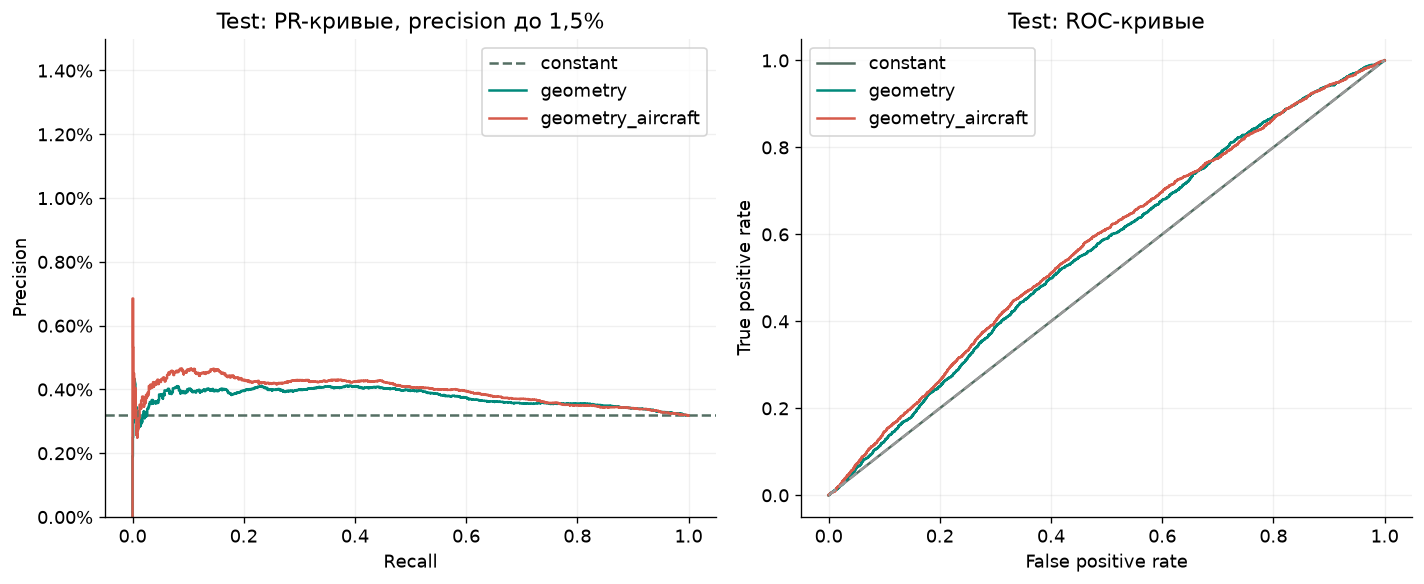

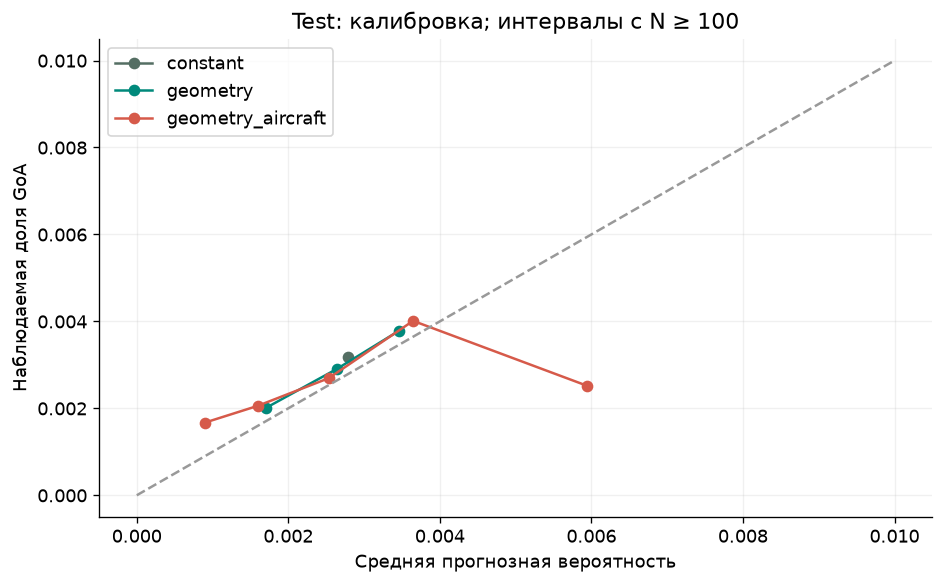

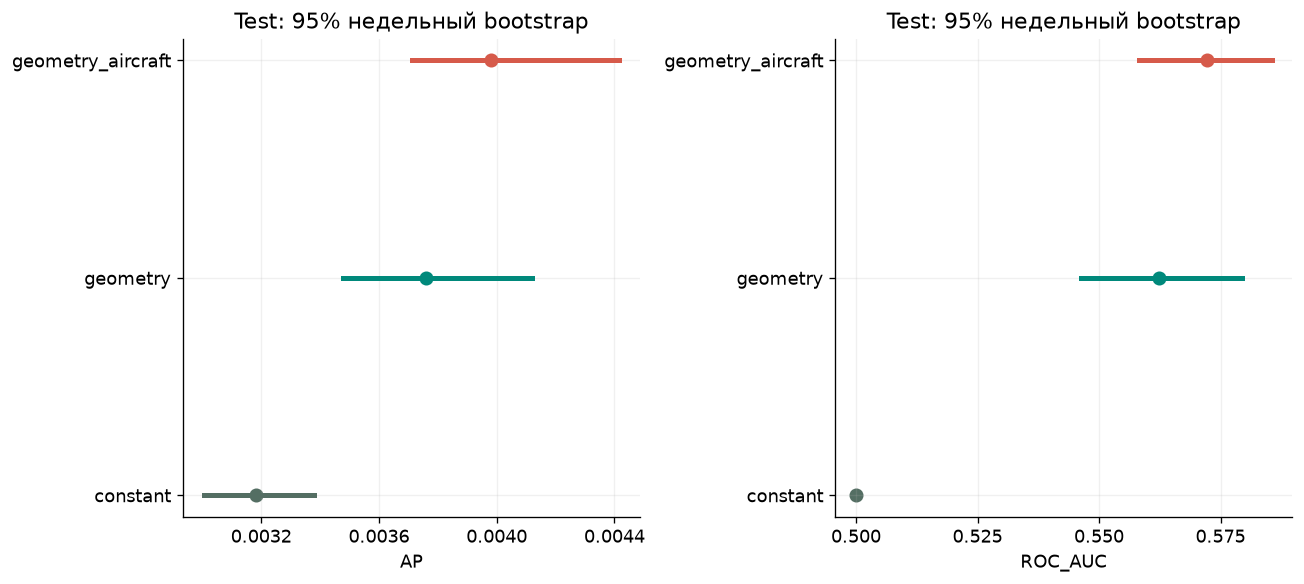

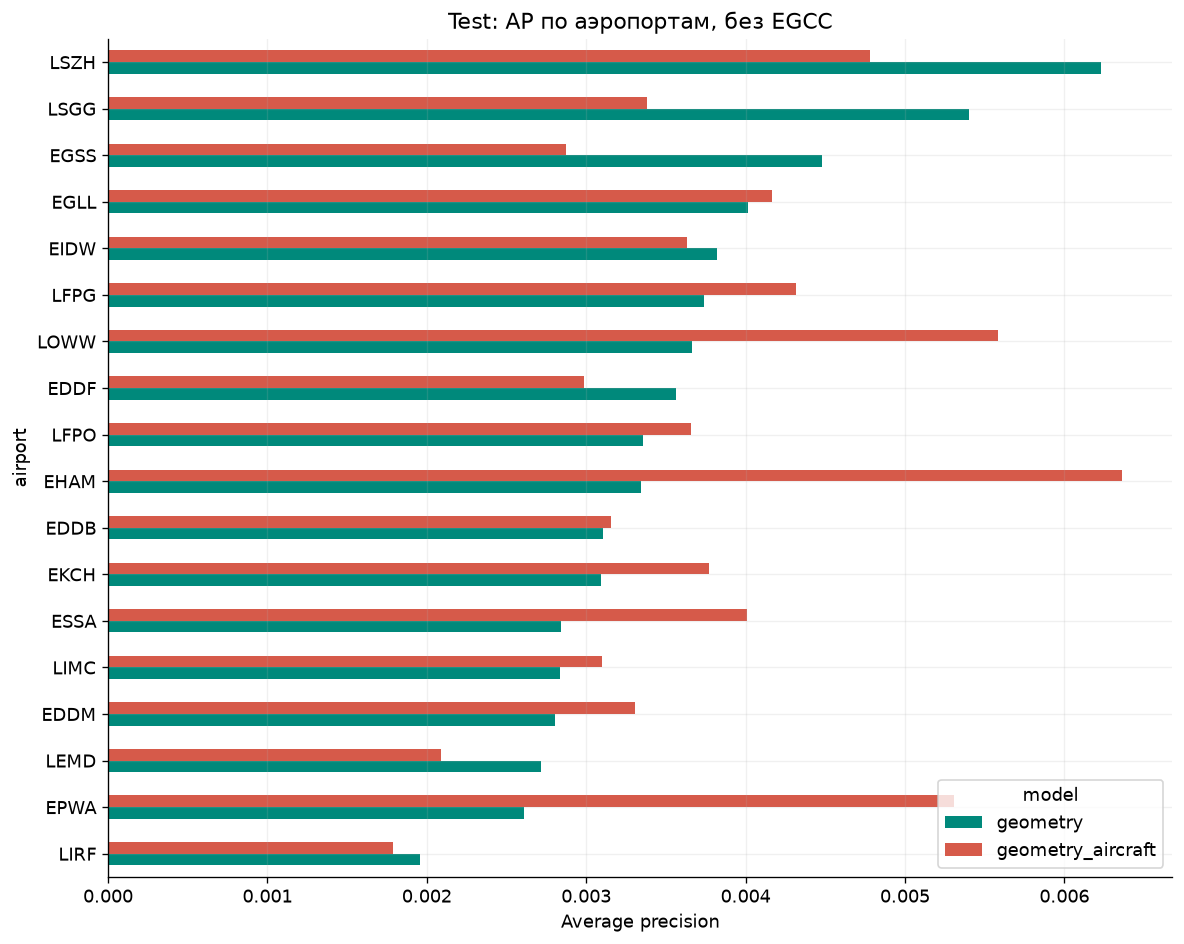

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for name,p in test_predictions.items():
    precision,recall,_=precision_recall_curve(ytest,p)
    # Прореживаем только изображение, сами метрики рассчитаны по всем порогам.
    take=np.unique(np.r_[np.arange(0,len(recall)-1,max(1,len(recall)//2000)),len(recall)-2])
    if name=='constant':
        axes[0].axhline(ytest.mean(),label=name,color=COLORS[name],linestyle='--')
    else:
        axes[0].step(recall[take],precision[take],where='post',label=name,color=COLORS[name])
    fp,tp,_=roc_curve(ytest,p)
    axes[1].plot(fp,tp,label=name,color=COLORS[name])
axes[0].set(xlabel='Recall',ylabel='Precision',title='Test: PR-кривые, precision до 1,5%',ylim=(0,.015))
from matplotlib.ticker import PercentFormatter,MaxNLocator
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Test: ROC-кривые')
axes[1].plot([0,1],[0,1],color='#999999',linestyle='--')
for ax in axes:ax.legend()
save('24_baseline_pr_roc')
fig,ax=plt.subplots(figsize=(8,5))
for name in test_predictions:
    a=calibration[calibration.split.eq('test')&calibration.model.eq(name)&calibration.rows.ge(100)]
    ax.plot(a.mean_predicted,a.observed,'o-',label=name,color=COLORS[name])
maximum=max(.01,float(calibration[calibration.split.eq('test')&calibration.rows.ge(100)][['mean_predicted','observed']].max().max()))
ax.plot([0,maximum],[0,maximum],color='#999999',linestyle='--')
ax.set(xlabel='Средняя прогнозная вероятность',ylabel='Наблюдаемая доля GoA',title='Test: калибровка; интервалы с N ≥ 100');ax.legend()
save('25_baseline_calibration')
fig,axes=plt.subplots(1,2,figsize=(11,5))
test=metrics[metrics.split.eq('test')].set_index('model')
for ax,metric in zip(axes,['AP','ROC_AUC']):
    names=list(test.index);ci=intervals[intervals.metric.eq(metric)].set_index('model')
    for i,name in enumerate(names):
        ax.plot([ci.loc[name,'lower'],ci.loc[name,'upper']],[i,i],color=COLORS[name],lw=3)
        ax.scatter(test.loc[name,metric],i,color=COLORS[name],s=55)
    ax.set_yticks(range(len(names)),names);ax.set_xlabel(metric);ax.set_title('Test: 95% недельный bootstrap')
    ax.xaxis.set_major_locator(MaxNLocator(4))
save('26_baseline_intervals')
a=airports.pivot(index='airport',columns='model',values='AP').sort_values('geometry')
a[['geometry','geometry_aircraft']].plot.barh(figsize=(10,8),color=[COLORS['geometry'],COLORS['geometry_aircraft']])
plt.xlabel('Average precision');plt.title('Test: AP по аэропортам, без EGCC');save('27_baseline_airport_ap')


In [7]:
assert sha(DATA)==plan['input_sha256'] and sha(split_path)==plan['split_file_sha256']
assert len(meta['test'])==split_expected.loc['test','rows']
for name in test_predictions:
    a=airports[airports.model.eq(name)]
    assert a.rows.sum()==len(ytest) and a.goa.sum()==int(ytest.sum())
    m=metrics[metrics.split.eq('test')&metrics.model.eq(name)].iloc[0]
    assert int(m.tp+m.fp+m.fn+m.tn)==len(ytest)
verification={'input_sha256':plan['input_sha256'],'split_sha256':plan['split_file_sha256'],
 'signature':signature,'prediction_sha256':sha(prediction_path),'environment':environment,
 'rows_train':len(ytrain),'rows_validation':len(yvalid),'rows_test':len(ytest),
 'goa_test':int(ytest.sum()),'fit_split':'train','selection_split':'validation',
 'test_used_for_selection':False,'converged_all':True,'same_test_rows_all_models':True,
 'airport_balances_passed':True,'weighted_metrics_match_sklearn':True,
 'bootstrap_replicates':1000,'bootstrap_weeks':nweeks,'operational_availability_verified':False,
 'baseline_training_performed':True,'input_unchanged':True,'models':['constant']+list(models)}
(R/'baseline_verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
text=f"""# Первый ретроспективный baseline

Выбор C и порогов выполнен только validation, fit только train. Решение
сохранено до test-метрик; все модели оценены на одних {len(ytest):,} строках /
{int(ytest.sum()):,} GoA. Сходимость всех кандидатов подтверждена.

{metrics[metrics.split.eq('test')][['model','AP','ROC_AUC','Brier','precision','recall','alert_rate']].to_string(index=False)}

Парные разности geometry_aircraft − geometry, 95% bootstrap недель:

{pd.DataFrame(delta).to_string(index=False)}

Это результаты фиксированных моделей и выбранной популяции, не причинный эффект
типа самолета и не доказательство эксплуатационной полезности. Блоки недель
не учитывают всю зависимость по самолетам. Историческое время получения
признаков не подтверждено; EGCC в test отсутствует, 2023 год неполный.
Повышение AP не заменяет проверку калибровки и приемлемой доли ошибок FP.
Исходные данные, метки и выборка A не изменены. Локальные коэффициенты и
построчные test-прогнозы исключены из Git. Дальнейший подбор по этому test
потребовал бы нового независимого периода для честной финальной оценки.
"""
(R/'baseline_findings.md').write_text(text,encoding='utf-8');display(Markdown(text))


# Первый ретроспективный baseline

Выбор C и порогов выполнен только validation, fit только train. Решение
сохранено до test-метрик; все модели оценены на одних 546,577 строках /
1,739 GoA. Сходимость всех кандидатов подтверждена.

            model       AP  ROC_AUC    Brier  precision   recall  alert_rate
         constant 0.003182 0.500000 0.003172   0.003182 1.000000    1.000000
         geometry 0.003759 0.562344 0.003171   0.004083 0.441633    0.344171
geometry_aircraft 0.003980 0.572297 0.003171   0.003671 0.020127    0.017445

Парные разности geometry_aircraft − geometry, 95% bootstrap недель:

 metric                         contrast         lower        upper  valid_replicates
     AP geometry_aircraft minus geometry  2.415236e-05 4.763646e-04              1000
ROC_AUC geometry_aircraft minus geometry  2.290236e-03 1.811240e-02              1000
  Brier geometry_aircraft minus geometry -2.014084e-07 2.690183e-08              1000

Это результаты фиксированных моделей и выбранной популяции, не причинный эффект
типа самолета и не доказательство эксплуатационной полезности. Блоки недель
не учитывают всю зависимость по самолетам. Историческое время получения
признаков не подтверждено; EGCC в test отсутствует, 2023 год неполный.
Повышение AP не заменяет проверку калибровки и приемлемой доли ошибок FP.
Исходные данные, метки и выборка A не изменены. Локальные коэффициенты и
построчные test-прогнозы исключены из Git. Дальнейший подбор по этому test
потребовал бы нового независимого периода для честной финальной оценки.
